In [110]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [112]:
# Load dataset with a different encoding
df = pd.read_csv('sales_data_sample.csv', encoding ="unicode_escape")
df

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2818,10350,20,100.00,15,2244.40,12/2/2004 0:00,Shipped,4,12,2004,...,"C/ Moralzarzal, 86",NaN,Madrid,NaN,28034,Spain,EMEA,Freyre,Diego,Small
2819,10373,29,100.00,1,3978.51,1/31/2005 0:00,Shipped,1,1,2005,...,Torikatu 38,NaN,Oulu,NaN,90110,Finland,EMEA,Koskitalo,Pirkko,Medium
2820,10386,43,100.00,4,5417.57,3/1/2005 0:00,Resolved,1,3,2005,...,"C/ Moralzarzal, 86",NaN,Madrid,NaN,28034,Spain,EMEA,Freyre,Diego,Medium
2821,10397,34,62.24,1,2116.16,3/28/2005 0:00,Shipped,1,3,2005,...,1 rue Alsace-Lorraine,NaN,Toulouse,NaN,31000,France,EMEA,Roulet,Annette,Small


In [113]:
df = df.dropna()


In [114]:
# Select numerical columns for clustering
# Assume we are clustering based on 'SALES', 'QUANTITYORDERED', 'PRICEEACH'

X = df[[ 'QUANTITYORDERED', 'PRICEEACH','SALES']]

In [115]:

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [116]:
# 5. Elbow method
inertia = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

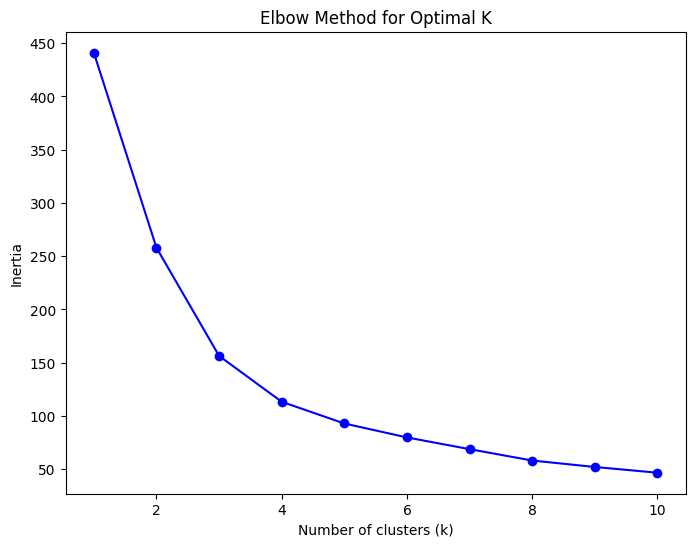

In [117]:
# 6. Plot elbow graph
plt.figure(figsize=(8, 6))
plt.plot(K, inertia, "bo-")

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.show()

In [118]:
# 7. Apply K-Means
optimal_k = 4

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

# 8. Display cluster assignments
df[['SALES', 'QUANTITYORDERED', 'PRICEEACH', 'Cluster']]

,SALES,QUANTITYORDERED,PRICEEACH,Cluster
10,3965.66,37,100.00,2
21,1451.00,20,72.55,0
40,4905.39,21,100.00,2
47,3944.70,30,100.00,2
51,2416.56,24,100.00,2
...,...,...,...,...
2667,3268.00,43,76.00,3
2673,1747.20,26,67.20,0
2685,5001.92,44,100.00,1
2764,4277.35,35,100.00,2


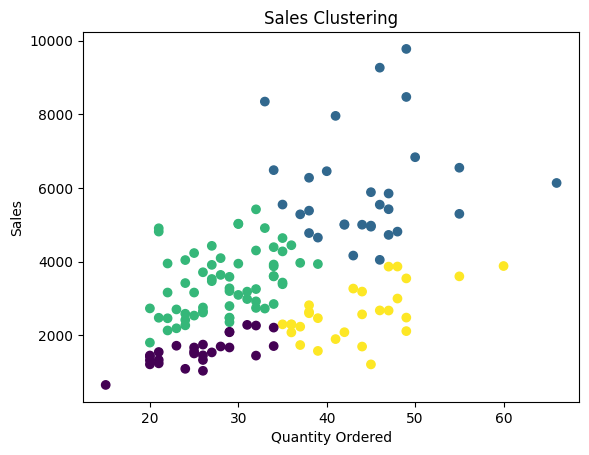

In [121]:
# 9. Visualize clusters
plt.scatter(df["QUANTITYORDERED"],
            df["SALES"],
            c=df["Cluster"])

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("Sales Clustering")
plt.show()